# 03 · Generation smoke test (Phase 1)

Runs the corrected generator (`src/generation.py`) on the real checkpoints. The generation script of the first submission (`src/archive/generation_test_8cb.py`) did not undo the delay pattern, used controls on a 0–9 scale and started from an empty prompt; none of its audio is used anymore.

**Part A — oracle check on real weights.** The generation loop is run on a real segment but writes the real codes instead of sampling. Its logits must equal those of one teacher-forced forward pass (the computation behind Table 1). `tests/test_generation.py` checks the same on a small random model; this repeats it with the trained weights on the GPU.

**Part B — paired generation.** From a real 1-second prompt, four control profiles are generated with the same seed and shared random numbers (`shared_noise=True`), so the clips differ only because the controls differ. Audio is written without peak normalisation, because tension is defined on the signal level.

**Part C — speed.** Real-time factor (generation time / generated audio duration) on the Kaggle GPU.

This notebook is a smoke test: the systematic measurement of control adherence is Phase 2.

**Kaggle settings:** GPU T4, Internet on. **Inputs:** `slakh-tensors-final`, `ost-tensors-sky-w3`, models `secunda-finetuned-on-slakh` and `secunda-finetuned-on-ost-v2`.

In [1]:
# ── Repository bootstrap: make src/ importable on Kaggle and locally ──
# On Kaggle the repository is cloned into /kaggle/working (Internet must be
# enabled in the notebook settings). Locally, set SECUNDA_REPO_DIR to the
# repository root and nothing is cloned.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/DanBracs7/Adaptive-Secunda-Synth.git"
REPO_BRANCH = "revision"  # switch to "main" after merging the revision
REPO_DIR = Path(os.environ.get("SECUNDA_REPO_DIR", "/kaggle/working/Adaptive-Secunda-Synth"))

if not (REPO_DIR / "src").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )

sys.path.insert(0, str(REPO_DIR / "src"))

commit = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
    capture_output=True,
    text=True,
).stdout.strip()

print("Repository:", REPO_DIR)
print("Commit:", commit or "unknown (not a git checkout)")

Cloning into '/kaggle/working/Adaptive-Secunda-Synth'...


Repository: /kaggle/working/Adaptive-Secunda-Synth
Commit: 4e17e4e


In [2]:
from paths import get_path, running_on_kaggle, source_roots_for_split

if running_on_kaggle():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "encodec==0.1.1"], check=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 67.8 MB/s eta 0:00:00


In [3]:
import csv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Audio, display

from control_features import KNOWN_TENSION_RMS_STATS, frame_rms, normalize_tension
from frame_codec import NUM_CODEBOOKS, CodebookSerializer
from generation import (
    FRAME_RATE,
    SAMPLE_RATE,
    Timer,
    _run_delayed_loop,
    constant_control,
    decode_codes,
    generate_codes,
    load_codec,
    load_prompt,
    ramp_control,
    real_time_factor,
    save_wav,
    step_control,
    with_prompt_controls,
)
from training_utils import load_checkpoint_model, prepare_batch_for_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = get_path("output_dir") / "generation_smoke_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOTAL_FRAMES = 750          # 10 s, the training segment length
PROMPT_FRAMES = 75          # 1 s of real audio
PROMPT_START_FRAME = 1500   # 20 s into the track, past most intros
SEED = 0

# Low / high control levels: 10th / 90th percentiles of the Slakh train+val
# conditions (notebooks/02_control_statistics_audit.ipynb, Part A), so the
# requested values stay inside the training distribution. Phase 2 chooses
# the levels per source.
LOW = {"tension": 0.14, "combat_score": 0.21}
HIGH = {"tension": 0.77, "combat_score": 0.85}
STEP_FRAME = 375            # 5 s

# Tension of generated audio is measured with v1, the statistics of the
# largest block of Slakh training tensors and of all OST tensors
# (notebook 02, Part B; the five versions differ by at most 0.019).
TENSION_STATS = KNOWN_TENSION_RMS_STATS["v1"]

Device: Tesla T4


In [4]:
# One prompt per checkpoint, taken from tracks the model was not trained on:
# the first Slakh test track for Slakh-FT and the first Witcher 3
# validation track for OST-FT.
with open(get_path("manifest"), newline="", encoding="utf-8") as file:
    manifest_rows = list(csv.DictReader(file))


def first_row(source, split):
    rows = [row for row in manifest_rows if row["source"] == source and row["split"] == split]
    return sorted(rows, key=lambda row: row["path"])[0]


SETUPS = {
    "Slakh-FT": {"checkpoint": get_path("ckpt_slakh_ft"), "row": first_row("slakh", "test")},
    "OST-FT": {"checkpoint": get_path("ckpt_ost_ft"), "row": first_row("witcher3", "val")},
}

for name, setup in SETUPS.items():
    row = setup["row"]
    setup["tensor_path"] = source_roots_for_split(row["split"])[row["source"]] / Path(row["path"]).name
    print(f"{name:9s} prompt: {row['path']} ({row['track_id']}), frames {PROMPT_START_FRAME}-"
          f"{PROMPT_START_FRAME + PROMPT_FRAMES}")

codec = load_codec(device)

Slakh-FT  prompt: slakh/test_000.pt (Track01982), frames 1500-1575
OST-FT    prompt: witcher3/witcher3_005.pt (06 Commanding the Fury), frames 1500-1575


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Downloading: "https://dl.fbaipublicfiles.com/encodec/v0/encodec_24khz-d7cc33bc.th" to /root/.cache/torch/hub/checkpoints/encodec_24khz-d7cc33bc.th


100%|██████████| 88.9M/88.9M [00:00<00:00, 201MB/s]


## Part A — oracle check on real weights

In [5]:
serializer = CodebookSerializer()
oracle_rows = []

for name, setup in SETUPS.items():
    model, _ = load_checkpoint_model(setup["checkpoint"], device)
    setup["model"] = model

    codes, tension, combat_score = load_prompt(setup["tensor_path"], PROMPT_START_FRAME, TOTAL_FRAMES)
    batch = {"tokens": codes, "tension": tension[None], "combat_score": combat_score[None]}

    with torch.inference_mode():
        prepared = prepare_batch_for_model(batch, serializer, device)
        teacher_forced = model(
            input_codes=prepared["input_codes"],
            input_tension=prepared["input_tension"],
            input_combat=prepared["input_combat"],
            target_tension=prepared["target_tension"],
            target_combat=prepared["target_combat"],
        )

    real_delayed = serializer.delay(codes).to(device)
    differences = []
    stepwise_ce = torch.zeros(NUM_CODEBOOKS, device=device)
    teacher_forced_ce = torch.zeros(NUM_CODEBOOKS, device=device)
    cell_count = torch.zeros(NUM_CODEBOOKS, device=device)

    def write_real_codes(step, logits, frame_index, to_sample):
        reference = teacher_forced[:, :, step - 1, :]
        target = real_delayed[:, :, step]
        differences.append((logits - reference)[:, to_sample].abs().max().item())
        for q in torch.nonzero(to_sample).flatten().tolist():
            stepwise_ce[q] += torch.nn.functional.cross_entropy(logits[:, q], target[:, q])
            teacher_forced_ce[q] += torch.nn.functional.cross_entropy(reference[:, q], target[:, q])
            cell_count[q] += 1
        return target

    with torch.inference_mode(), Timer() as timer:
        _run_delayed_loop(
            model, codes[:, :, :PROMPT_FRAMES].to(device),
            tension[None].to(device), combat_score[None].to(device), write_real_codes,
        )

    oracle_rows.append({
        "checkpoint": name,
        "max_abs_logit_difference": max(differences),
        "stepwise_ce_mean": (stepwise_ce / cell_count).mean().item(),
        "teacher_forced_ce_mean": (teacher_forced_ce / cell_count).mean().item(),
        "seconds": round(timer.seconds, 1),
    })

oracle = pd.DataFrame(oracle_rows)
oracle.to_csv(OUTPUT_DIR / "oracle_check.csv", index=False)
print(oracle.to_string(index=False))

/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


checkpoint  max_abs_logit_difference  stepwise_ce_mean  teacher_forced_ce_mean  seconds
  Slakh-FT                  0.000031          5.279104                5.279104     14.1
    OST-FT                  0.000027          5.904685                5.904685     14.1


## Part B — paired generation with four control profiles

In [6]:
def make_profiles(prompt_tension, prompt_combat):
    """Requested tension / combat tracks; the prompt frames keep their own controls."""
    profiles = {
        "chill": (LOW["tension"], LOW["tension"], LOW["combat_score"], LOW["combat_score"], "constant"),
        "combat": (HIGH["tension"], HIGH["tension"], HIGH["combat_score"], HIGH["combat_score"], "constant"),
        "chill_to_combat_ramp": (LOW["tension"], HIGH["tension"], LOW["combat_score"], HIGH["combat_score"], "ramp"),
        "chill_to_combat_step": (LOW["tension"], HIGH["tension"], LOW["combat_score"], HIGH["combat_score"], "step"),
    }
    tracks = {}
    for name, (t_start, t_end, c_start, c_end, shape) in profiles.items():
        if shape == "constant":
            tension, combat = constant_control(t_start, TOTAL_FRAMES), constant_control(c_start, TOTAL_FRAMES)
        elif shape == "ramp":
            tension = ramp_control(t_start, t_end, TOTAL_FRAMES, ramp_start_frame=PROMPT_FRAMES)
            combat = ramp_control(c_start, c_end, TOTAL_FRAMES, ramp_start_frame=PROMPT_FRAMES)
        else:
            tension = step_control(t_start, t_end, TOTAL_FRAMES, STEP_FRAME)
            combat = step_control(c_start, c_end, TOTAL_FRAMES, STEP_FRAME)
        tracks[name] = (with_prompt_controls(tension, prompt_tension),
                        with_prompt_controls(combat, prompt_combat))
    return tracks


def measured_tension(waveform):
    """Frame RMS of the decoded audio mapped with the training statistics (no peak normalisation)."""
    num_frames = int(round(waveform.shape[-1] / (SAMPLE_RATE / FRAME_RATE)))
    return normalize_tension(frame_rms(waveform, num_frames), TENSION_STATS)


generation_rows = []
clips = {}

for name, setup in SETUPS.items():
    model = setup["model"]
    prompt, prompt_tension, prompt_combat = load_prompt(setup["tensor_path"], PROMPT_START_FRAME, PROMPT_FRAMES)
    tracks = make_profiles(prompt_tension, prompt_combat)
    profile_names = list(tracks)

    tension = torch.stack([tracks[p][0] for p in profile_names]).to(device)
    combat = torch.stack([tracks[p][1] for p in profile_names]).to(device)
    prompts = prompt.expand(len(profile_names), -1, -1).to(device)

    with Timer() as timer:
        codes = generate_codes(model, prompts, tension, combat, seed=SEED, shared_noise=True)
    setup["batched_seconds"] = timer.seconds
    setup["batch_size"] = len(profile_names)

    # Paired design check on the GPU: the first profile generated alone
    # must give the same codes as inside the batch.
    with Timer() as timer:
        alone = generate_codes(model, prompts[:1], tension[:1], combat[:1], seed=SEED, shared_noise=True)
    setup["single_seconds"] = timer.seconds
    same_frames = (alone[0] == codes[0]).all(dim=0).float().mean().item()
    print(f"{name}: '{profile_names[0]}' alone vs in batch: {same_frames:.1%} identical frames")

    waveforms = decode_codes(codec, codes)

    # Codec reference: the real Q0-Q7 codes of the same 10 s, decoded the same way.
    real_codes, real_tension, _ = load_prompt(setup["tensor_path"], PROMPT_START_FRAME, TOTAL_FRAMES)
    reference = decode_codes(codec, real_codes)[0]

    for index, profile in enumerate(profile_names + ["real_audio_codec_reference"]):
        waveform = waveforms[index] if index < len(profile_names) else reference
        path = OUTPUT_DIR / f"{name}_{profile}.wav"
        clipped = save_wav(path, waveform)
        measured = measured_tension(waveform)
        requested = tracks[profile][0].numpy() if profile in tracks else real_tension.numpy()
        clips[(name, profile)] = (path, measured, requested)
        after_prompt = slice(PROMPT_FRAMES, TOTAL_FRAMES)
        generation_rows.append({
            "checkpoint": name,
            "profile": profile,
            "rms_dbfs": 20 * np.log10(float(waveform.pow(2).mean().sqrt()) + 1e-12),
            "peak": float(waveform.abs().max()),
            "clipped_fraction": clipped,
            "requested_tension_mean": float(requested[after_prompt].mean()),
            "measured_tension_mean": float(measured[after_prompt].mean()),
        })

generation = pd.DataFrame(generation_rows)
generation.to_csv(OUTPUT_DIR / "generated_clips.csv", index=False)
print(generation.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

Slakh-FT: 'chill' alone vs in batch: 100.0% identical frames
OST-FT: 'chill' alone vs in batch: 100.0% identical frames
checkpoint                    profile  rms_dbfs  peak  clipped_fraction  requested_tension_mean  measured_tension_mean
  Slakh-FT                      chill   -25.371 0.821             0.000                   0.140                  0.141
  Slakh-FT                     combat   -16.273 0.821             0.000                   0.770                  0.704
  Slakh-FT       chill_to_combat_ramp   -19.578 0.821             0.000                   0.455                  0.412
  Slakh-FT       chill_to_combat_step   -18.790 0.821             0.000                   0.490                  0.430
  Slakh-FT real_audio_codec_reference   -18.598 0.821             0.000                   0.461                  0.452
    OST-FT                      chill   -22.207 0.813             0.000                   0.140                  0.146
    OST-FT                     combat   -14.814

In [7]:
for (name, profile), (path, measured, requested) in clips.items():
    print(f"{name} · {profile}")
    display(Audio(str(path)))

Audio players removed from the committed copy to keep the repository small (about 6 MB).
The WAV files are written to OUTPUT_DIR (Kaggle output: generation_smoke_test/).


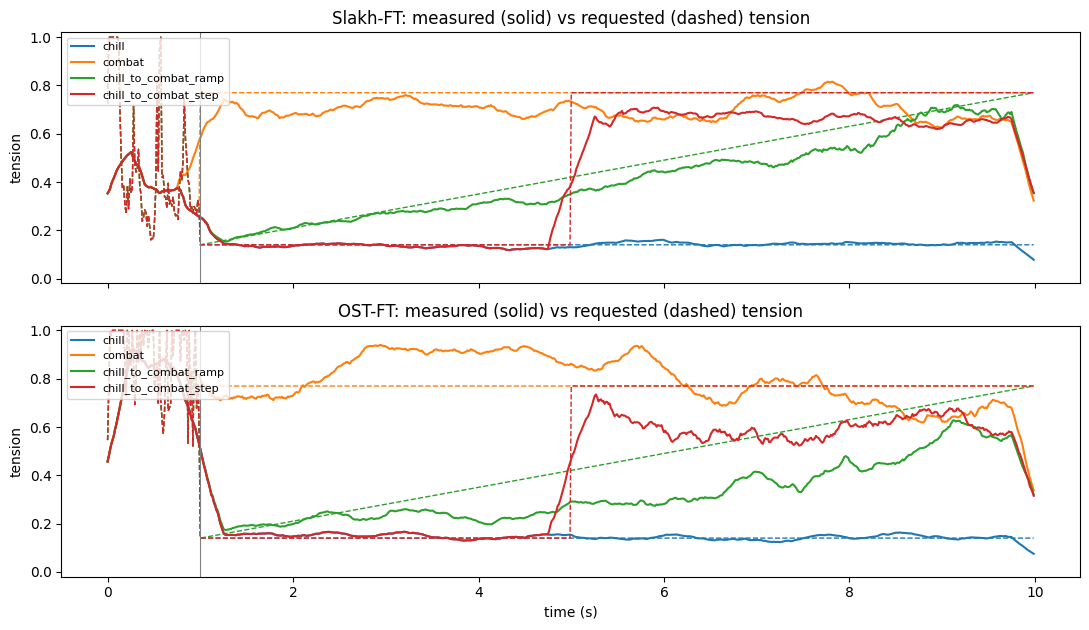

In [8]:
# Preview for Phase 2: tension measured on the generated audio (frame RMS,
# smoothed over 0.5 s) against the requested tension.
figure, axes = plt.subplots(len(SETUPS), 1, figsize=(11, 3.2 * len(SETUPS)), sharex=True)
seconds = np.arange(TOTAL_FRAMES) / FRAME_RATE
kernel = np.ones(38) / 38

for axis, name in zip(np.atleast_1d(axes), SETUPS):
    for (clip_name, profile), (path, measured, requested) in clips.items():
        if clip_name != name or profile == "real_audio_codec_reference":
            continue
        line, = axis.plot(seconds[:len(measured)], np.convolve(measured, kernel, mode="same"), label=profile)
        axis.plot(seconds, requested, color=line.get_color(), linestyle="--", linewidth=1)
    axis.axvline(PROMPT_FRAMES / FRAME_RATE, color="grey", linewidth=0.8)
    axis.set_title(f"{name}: measured (solid) vs requested (dashed) tension")
    axis.set_ylabel("tension")
    axis.set_ylim(-0.02, 1.02)
    axis.legend(fontsize=8, loc="upper left")

axes[-1].set_xlabel("time (s)")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "tension_preview.png", dpi=150)
plt.show()

## Part C — speed

In [9]:
generated_frames = TOTAL_FRAMES - PROMPT_FRAMES
speed_rows = []
for name, setup in SETUPS.items():
    speed_rows.append({
        "checkpoint": name,
        "batch_size": 1,
        "seconds": round(setup["single_seconds"], 1),
        "real_time_factor": real_time_factor(setup["single_seconds"], generated_frames, 1),
    })
    speed_rows.append({
        "checkpoint": name,
        "batch_size": setup["batch_size"],
        "seconds": round(setup["batched_seconds"], 1),
        "real_time_factor": real_time_factor(setup["batched_seconds"], generated_frames, setup["batch_size"]),
    })

speed = pd.DataFrame(speed_rows)
speed.to_csv(OUTPUT_DIR / "speed.csv", index=False)
print(f"{generated_frames} generated frames ({generated_frames / FRAME_RATE:.0f} s) per clip")
print(speed.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

675 generated frames (9 s) per clip
checkpoint  batch_size  seconds  real_time_factor
  Slakh-FT           1    15.20              1.69
  Slakh-FT           4    51.90              1.44
    OST-FT           1    14.80              1.65
    OST-FT           4    53.50              1.49


### How to read the result

- **Part A:** `max_abs_logit_difference` should be at floating-point level (≲1e-3 on GPU) and the two cross-entropies equal: generation then predicts every cell from the same context and conditions as training.
- **Part B:** the identical-frames check should be 100% (a value slightly below can come from GPU kernels choosing a different summation order for another batch size). `measured_tension_mean` compared with `requested_tension_mean` is only a preview; Phase 2 measures tension and combat score systematically, over many prompts and seeds.
- **Part C:** a real-time factor below 1 means faster than real time.

### Results of this run

**Part A.** Maximum |Δlogit| between the generation loop and the teacher-forced pass: 3.1e-5 (Slakh-FT) and 2.7e-5 (OST-FT), at float32 precision; the cross-entropy on the 10-s segment is identical (5.279 and 5.905). Generation predicts every cell from the same context and conditions as training.

**Part B.** The paired check is 100% for both checkpoints: with `shared_noise=True` a clip is the same whether generated alone or in a batch, so the four profiles differ only because of their controls.

Mean tension after the prompt (requested → measured on the generated audio):

| Profile | Slakh-FT | OST-FT |
|---|---|---|
| chill (0.14) | 0.141 | 0.146 |
| combat (0.77) | 0.704 | 0.792 |
| ramp 0.14 → 0.77 (mean 0.455) | 0.412 | 0.328 |
| step at 5 s (mean 0.490) | 0.430 | 0.405 |

The constant levels are reached within about 0.3 s of the end of the prompt. After the step the measured tension rises within a few tenths of a second (the curves are smoothed over 0.5 s, so their rise starts slightly before 5 s). The ramp is followed with a lag: Slakh-FT stays about 0.1 below the request in the middle of the clip, OST-FT stays near 0.2–0.3 until 6 s and then rises. One prompt and one seed per checkpoint, and tension is a signal-level control: these numbers show that the corrected generator responds to the controls, not how reliably. Phase 2 measures tension and combat score over many prompts and seeds.

**Part C.** Real-time factor on a T4: 1.65–1.69 for one clip, 1.44–1.49 per clip in a batch of four, i.e. generation is about 1.5× slower than real time. Each step re-runs the Transformer on the whole prefix (no key/value cache).